# Parameter Estimation

In [360]:
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd 
import pymc
from mpl_toolkits import mplot3d
import scipy 




# Model setup

In [361]:
# Input parameters
t = np.arange(0.3,60, step=0.3)
s = np.arange(0,3.0,step = 0.5)
num_config = 1
if (num_config==1):
    # default params
    M = 10
    D = 0.07
    L = 1.505
    tau = 30.1525
    model_params = [M,D,L,tau]
    print(model_params)

print(s)
print(t)

# Ouput parameters


[10, 0.07, 1.505, 30.1525]
[0.  0.5 1.  1.5 2.  2.5]
[ 0.3  0.6  0.9  1.2  1.5  1.8  2.1  2.4  2.7  3.   3.3  3.6  3.9  4.2
  4.5  4.8  5.1  5.4  5.7  6.   6.3  6.6  6.9  7.2  7.5  7.8  8.1  8.4
  8.7  9.   9.3  9.6  9.9 10.2 10.5 10.8 11.1 11.4 11.7 12.  12.3 12.6
 12.9 13.2 13.5 13.8 14.1 14.4 14.7 15.  15.3 15.6 15.9 16.2 16.5 16.8
 17.1 17.4 17.7 18.  18.3 18.6 18.9 19.2 19.5 19.8 20.1 20.4 20.7 21.
 21.3 21.6 21.9 22.2 22.5 22.8 23.1 23.4 23.7 24.  24.3 24.6 24.9 25.2
 25.5 25.8 26.1 26.4 26.7 27.  27.3 27.6 27.9 28.2 28.5 28.8 29.1 29.4
 29.7 30.  30.3 30.6 30.9 31.2 31.5 31.8 32.1 32.4 32.7 33.  33.3 33.6
 33.9 34.2 34.5 34.8 35.1 35.4 35.7 36.  36.3 36.6 36.9 37.2 37.5 37.8
 38.1 38.4 38.7 39.  39.3 39.6 39.9 40.2 40.5 40.8 41.1 41.4 41.7 42.
 42.3 42.6 42.9 43.2 43.5 43.8 44.1 44.4 44.7 45.  45.3 45.6 45.9 46.2
 46.5 46.8 47.1 47.4 47.7 48.  48.3 48.6 48.9 49.2 49.5 49.8 50.1 50.4
 50.7 51.  51.3 51.6 51.9 52.2 52.5 52.8 53.1 53.4 53.7 54.  54.3 54.6
 54.9 55.2 55.5 55.8 56.1 

In [362]:
class environ():
    """
    Environmental model
    Source: https://www.sfu.ca/~ssurjano/environ.html
    params: [M,D, L, t]
    """
    def __init__(self, params, s, t):
        self.M = params[0]
        self.D = params[1]
        self.L = params[2]
        self.tau = params[3]
        self.s = s
        self.t = t
        self.ds = len(s)
        self.dt = len(t)
        self.dY = self.ds*self.dt
        #output Y
        self.Y = np.zeros([self.ds,self.dt])


    
    def f(self,s,t) -> float:
        def C(s,t)-> float:
            a1 =self.M/np.sqrt(4*np.pi*self.D*t)
            a2 = np.exp(-(np.square(s))/(4*self.D*t)) 
            if (self.tau < t):
                a3 = self.M/np.sqrt(4*np.pi*self.D*(t-self.tau))
                a4 = np.exp(-(np.square((s-self.L)))/(4*self.D*(t-self.tau)))
            else:
                a3 = 0
                a4 = 0
            c = a1*a2 + a3*a4
            return c
        f_eval = np.sqrt(4*np.pi)*C(s,t)
        return f_eval
    
    def run(self)-> np.ndarray:
        for i in range(self.ds):
            for j in range(self.dt):
                self.Y[i,j] = self.f(s[i],t[j])
        y_vector = self.Y.flatten()
        return y_vector
         


         

In [363]:
model = environ(model_params, s ,t)
y_vector = model.run()
y_matrix = model.Y
T,S = np.meshgrid(t,s)

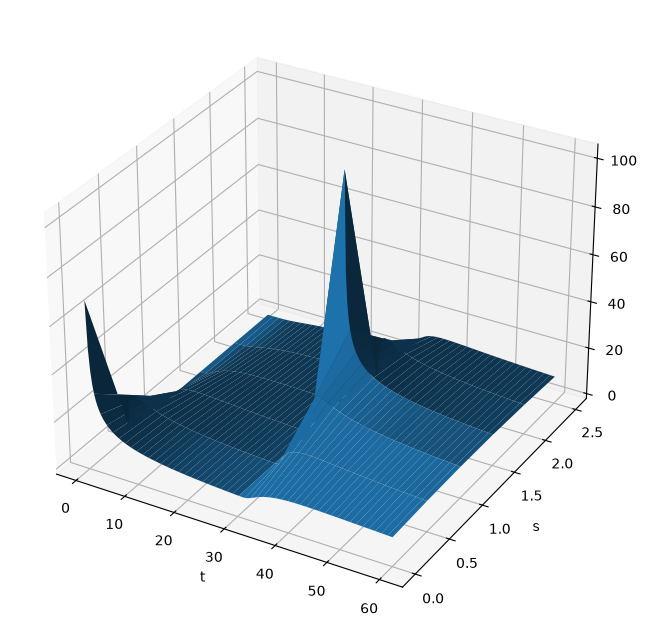

In [364]:
fig = plt.figure(figsize=(14,8))
ax = plt.axes(projection = '3d')
ax.plot_surface(T,S,y_matrix)
ax.set_xlabel('t')
ax.set_ylabel('s')
plt.show()

# Metropolis-Hastings Algorithm

In [365]:
np.random.seed(42)
#np.random.seed(123)

In [366]:
def MH(ground_truth:np.ndarray, measurements: np.ndarray, theta_0: np.ndarray, proposal_params:tuple, num_iterations:int):

    theta_samples = [0]*num_iterations
    theta_samples[0] = theta_0
    accepted_list = []

    def proposal(mu:float,sigma:float, shape:tuple): 
        #assume normal distribution for proposal (instrumental) distribution
        # draw a candidate from this distribution
        #candidate = theta_0 + np.random.normal(loc = mu, scale = sigma , size =shape )
        candidate = np.random.normal(loc = mu, scale = sigma , size =shape )
       
        return candidate

    def target_distribution(theta):
        new_model = environ([theta[0],0.07,1.505,30.1525],s,t)
        predictions = new_model.run()
        loglikelihood = np.sum(scipy.stats.norm.logpdf(measurements, loc=predictions , scale = 1))
        logprior = scipy.stats.uniform.logpdf(theta, loc = 7, scale = 6)
        #logprior = scipy.stats.norm.logpdf(theta, loc = 10, scale = 1)
        return loglikelihood+logprior

    def acceptance_ratio(n,theta_prime,mu,sigma):
        candidate_q_prob = scipy.stats.norm.logpdf(theta_prime, loc = mu, scale = sigma)
        current_q_prob = scipy.stats.norm.logpdf(theta_samples[n-1], loc = theta_prime, scale = sigma)
        candidate_target_prob = target_distribution(theta_prime)
        current_target_prob = target_distribution(theta_samples[n-1])
        ratio = (candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob)
        #ratio = np.exp((candidate_target_prob - current_target_prob)+(current_q_prob-candidate_q_prob))
        return ratio


    for n in range(1,num_iterations):
        theta_prime = proposal(theta_samples[n-1],proposal_params[1], theta_0.shape)

        #calculated using logs
        alpha = acceptance_ratio(n,theta_prime, theta_samples[n-1], proposal_params[1])
        u = np.random.random_sample(1) # draw from uniform distibrution U[0,1)
        condition = np.log(u) <= np.minimum(0, alpha)
        #condition = u <= np.minimum(1, alpha)
        accepted_list.append(condition)
        if (condition):
            theta_samples[n] = theta_prime
        else:
            theta_samples[n] = theta_samples[n-1]

    return theta_samples, accepted_list

In [367]:
num_config = 1
theta_0 = np.random.uniform(7,14,size= num_config) #[7 to 13] for estimating M # assume uniform prior distribution
#theta_0 =[0]
proposal_params = (theta_0,0.1)
num_iterations = 10000
measurements = y_vector + np.random.normal(0,1, len(y_vector))

chain, acceptance_list = MH(ground_truth = y_vector, measurements = measurements, theta_0=theta_0, proposal_params=proposal_params, num_iterations=num_iterations)

In [368]:
np.count_nonzero(acceptance_list)/ len(acceptance_list)

np.float64(0.28742874287428744)

# Convergence Evaluation

In [369]:
print(chain[-1])

[10.02086721]


In [370]:
np.mean(chain)

np.float64(10.008722257730042)

In [371]:
np.mean(y_vector-measurements)

np.float64(-0.02404572228188033)

<function matplotlib.pyplot.show(close=None, block=None)>

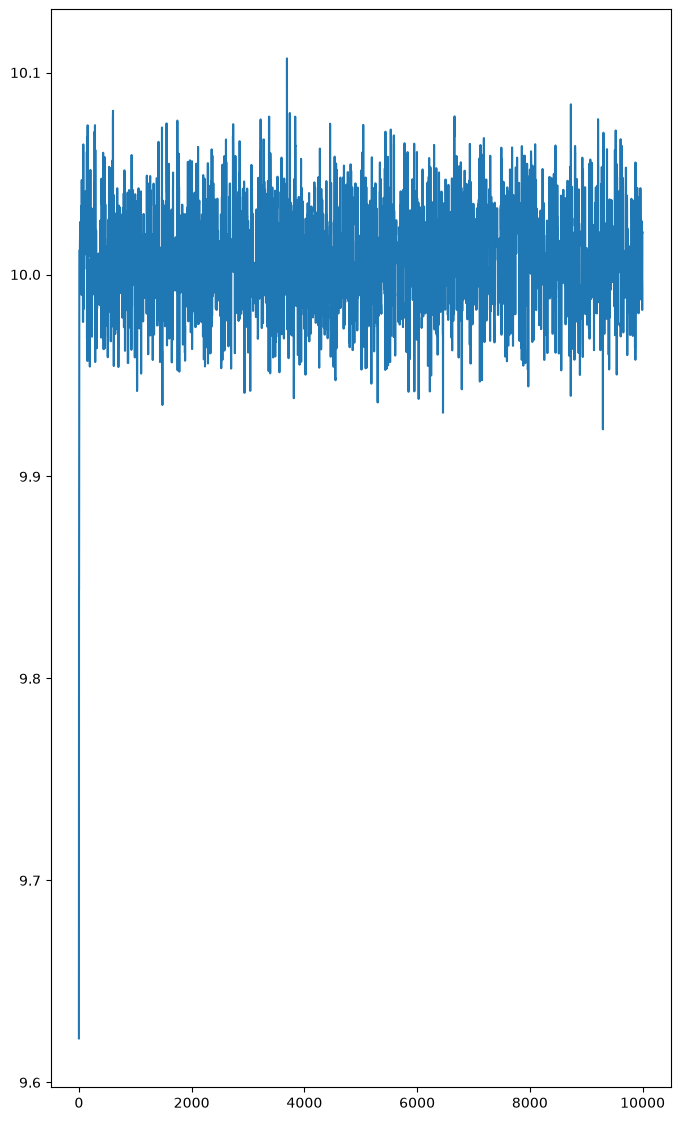

In [372]:
fig,ax = plt.subplots(ncols = 1, figsize=(8,14))
ax.plot(range(num_iterations), chain)
plt.show